# 09 · Balanceo de datos
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `07_train_sel`, `07_test_sel` · **Salida:** `09_train_smote` (y otros balanceados),
`reports/balanceo.json`.

Cuando la clase de interés es rara, la mayoría de los algoritmos la ignoran. Aquí vemos las
técnicas de balanceo, **con datos**, y una conclusión honesta sobre si ayudan.

> 🔒 **El balanceo se aplica SOLO a TRAIN. JAMÁS a TEST.** El test debe conservar la distribución
> real del negocio; un test balanceado responde a una pregunta que nadie hizo.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from collections import Counter
from pipeline_io import (
    TARGET, SEGMENT_COL, SEED, load_stage, save_stage, save_report, save_table, set_plot_theme,
    COLOR_OK, COLOR_BAD, COLOR_NEUTRAL, COLOR_WARN,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

set_plot_theme()

train_sel = load_stage("07_train_sel")
test_sel = load_stage("07_test_sel")
y_train = train_sel[TARGET]
y_test = test_sel[TARGET]
X_train_scaled = train_sel.drop(columns=[TARGET, SEGMENT_COL])
X_test_scaled = test_sel.drop(columns=[TARGET, SEGMENT_COL])

seed = SEED
target = TARGET

print("TRAIN:", X_train_scaled.shape, "| TEST:", X_test_scaled.shape)
print("Distribución train:", dict(Counter(y_train)))
print(f"Tasa de evento train: {y_train.mean():.1%}")


# ### 9.1 Balanceo de datos: el problema de los eventos raros
#
# > **Definición (del material del curso):** *"Se considera como evento raro cuando la categoría
# > de interés de la variable Target tiene una frecuencia relativa de entre 0.1% y 10%."*
#
# **Casos de uso reales de eventos raros:**
#
# | Caso de uso | Evento de interés | Tasa típica |
# |---|---|---|
# | Cobro de pólizas de seguros | El siniestro se cobra | ~1-5% |
# | Modelos de venta (cross-sell / up-sell) | El cliente compra el segundo producto | ~1-3% |
# | Fuga de clientes (churn) | El cliente se va | ~2-10% |
# | Detección de fallos de hardware | El componente falla | <1% |
# | Comportamiento fraudulento | La transacción es fraude | ~0.1-0.5% |
# | Detección de intrusión | El acceso es un ataque | <0.1% |
# | Diagnósticos médicos | El paciente tiene la enfermedad | variable, suele ser bajo |
#
# **¿Por qué molesta un evento raro?** Porque los algoritmos de clasificación minimizan el error
# **global**. Si el 99% de los casos son "no evento", la forma más barata de tener poco error es
# **ignorar la clase minoritaria por completo**. El modelo no está roto: está haciendo
# exactamente lo que le pediste. El problema es que le pediste lo incorrecto.

TRAIN: (447, 11) | TEST: (123, 11)
Distribución train: {0: 317, 1: 130}
Tasa de evento train: 29.1%


#### 9.1.1 Demostración: el accuracy engañoso

> *"un modelo con una proporción de target de 1% en el que se clasifique a todos como
> no-target, tendrá un nivel de Accuracy de 99%"*

No lo creamos por fe: lo demostramos. Construimos un dataset artificial al 1% submuestreando
la clase minoritaria y entrenamos un `DummyClassifier`, que es literalmente un modelo que
**no aprende nada** — solo responde siempre la clase mayoritaria.

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report

# --- Construimos un dataset artificial con 1% de evento ---
rng = np.random.default_rng(seed)                 # semilla propia: la celda es re-ejecutable

idx_mayoritaria = y_train[y_train == 0].index
idx_minoritaria = y_train[y_train == 1].index

# Queremos que la minoritaria sea el 1% del total: n_min = 0.01 * (n_may + n_min)
n_may = len(idx_mayoritaria)
n_min_objetivo = max(1, int(round(n_may * 0.01 / 0.99)))

idx_min_reducida = pd.Index(rng.choice(np.asarray(idx_minoritaria), size=n_min_objetivo, replace=False))
idx_raro = idx_mayoritaria.union(idx_min_reducida)

X_raro = X_train_scaled.loc[idx_raro]
y_raro = y_train.loc[idx_raro]

print('--- Dataset artificial de evento raro ---')
print(f'Total de registros    : {len(y_raro)}')
print(f'Casos de evento (y=1) : {int(y_raro.sum())}')
print(f'Tasa de evento        : {y_raro.mean():.4f}  ->  {y_raro.mean():.2%}')

--- Dataset artificial de evento raro ---


Total de registros    : 320
Casos de evento (y=1) : 3
Tasa de evento        : 0.0094  ->  0.94%


In [3]:
# --- Entrenamos un modelo que NO APRENDE NADA: siempre predice la clase mayoritaria ---
dummy = DummyClassifier(strategy='most_frequent', random_state=seed)
dummy.fit(X_raro, y_raro)

y_pred_dummy = dummy.predict(X_raro)
y_proba_dummy = dummy.predict_proba(X_raro)[:, 1]

print('=' * 62)
print('  MODELO "TONTO": predice SIEMPRE la clase 0 (crédito otorgado)')
print('=' * 62)
print(f'Accuracy : {accuracy_score(y_raro, y_pred_dummy):.4f}   <-- '
      f'¡{accuracy_score(y_raro, y_pred_dummy):.1%}! ¿Excelente modelo?')
print(f'Precision: {precision_score(y_raro, y_pred_dummy, zero_division=0):.4f}')
print(f'Recall   : {recall_score(y_raro, y_pred_dummy, zero_division=0):.4f}   <-- CERO. No detecta ni un solo caso.')
print(f'F1       : {f1_score(y_raro, y_pred_dummy, zero_division=0):.4f}')
print(f'ROC-AUC  : {roc_auc_score(y_raro, y_proba_dummy):.4f}   <-- 0.5 = azar puro')
print()
print('Matriz de confusión:')
cm = confusion_matrix(y_raro, y_pred_dummy)
print(pd.DataFrame(cm,
                   index=['Real: 0 (otorgado)', 'Real: 1 (NO otorgado)'],
                   columns=['Pred: 0', 'Pred: 1']).to_string())
print()
print(f'Predicciones de clase 1 (el evento que nos importa): {int(y_pred_dummy.sum())}')
print(f'Casos de evento que existían realmente             : {int(y_raro.sum())}')

  MODELO "TONTO": predice SIEMPRE la clase 0 (crédito otorgado)
Accuracy : 0.9906   <-- ¡99.1%! ¿Excelente modelo?
Precision: 0.0000
Recall   : 0.0000   <-- CERO. No detecta ni un solo caso.
F1       : 0.0000
ROC-AUC  : 0.5000   <-- 0.5 = azar puro

Matriz de confusión:
                       Pred: 0  Pred: 1
Real: 0 (otorgado)         317        0
Real: 1 (NO otorgado)        3        0

Predicciones de clase 1 (el evento que nos importa): 0
Casos de evento que existían realmente             : 3


**Este es el punto más importante de toda la sección.**

Un modelo con **99% de accuracy** que **no detecta ni un solo caso** de lo que nos interesa.
Si presentas ese 99% en un comité, te felicitan. Y el modelo es completamente inútil.

**Traducción a negocio:** en un modelo de fraude al 0.5%, "no hago nada" te da 99.5% de
accuracy y deja pasar el 100% del fraude. El accuracy no es una métrica mala *en general*:
es una métrica **inadecuada cuando las clases están desbalanceadas** o cuando los errores
tienen costos distintos. Y en negocio los errores **nunca** tienen el mismo costo: rechazar
a un buen cliente cuesta el margen perdido; aprobar a un moroso cuesta el capital completo.

**Qué mirar en su lugar:** Recall (¿cuántos casos reales capturo?), Precision (¿cuántas de mis
alertas son ciertas?), F1, **ROC-AUC** y sobre todo **PR-AUC** (mucho más informativa que
ROC-AUC cuando el evento es muy raro). Y ojo con la línea base: el ROC-AUC del modelo tonto es
0.5, pero su accuracy es 0.99. **Ninguna métrica se interpreta sin su línea base.**

#### 9.1.2 Muestreo de eventos raros

> *"Una práctica habitual de modelización predictiva es construir modelos usando una muestra
> con una proporción del suceso primario diferente de la población original."*

Es decir: **rompemos la representatividad a propósito**. Después de toda la teoría de muestreo del NB01
defendiendo que la muestra debe parecerse a la población, ahora hacemos lo contrario.

No es una contradicción, es un cambio de objetivo:
- Para **estimar** (¿cuál es mi tasa de morosidad?) → necesito representatividad. Sagrado.
- Para **entrenar** (¿qué patrón distingue a un moroso?) → me conviene que el algoritmo vea
  suficientes casos del evento para poder aprender el patrón.

**Y aquí viene la regla que no se negocia:** el balanceo se aplica **SOLO al conjunto de
entrenamiento**. El test conserva la proporción real, siempre, sin excepciones. Si balanceas
el test, tus métricas miden un mundo que no existe.

##### Undersampling (submuestreo)

> *"Seleccionar todas las observaciones target y un número menor de observaciones no target.
> Una práctica común es seleccionar una misma cantidad, para quedar en proporción 50/50 pero
> sólo se recomienda cuando la cantidad de observaciones target es muy grande. En la mayoría
> de los casos, basta con reducir la proporción del no target."*
>
> **Desventaja:** *"Podrían eliminarse registros potencialmente importantes."*

Tiras datos a la basura. Si tienes 5 millones de no-morosos, sobran. Si tienes 4,000,
cada uno cuenta y estás destruyendo información real por la que ya pagaste.

##### Tomek Links

> *"Elimina registros de la clase mayoritaria que se encuentren cerca a la frontera de decisión
> de las clases."*

Un *Tomek Link* es un par de puntos de **clases distintas** que son **mutuamente** el vecino
más cercano el uno del otro. Si dos puntos son vecinos inmediatos pero tienen etiquetas
opuestas, o uno es ruido o están en la frontera. Tomek elimina el de la clase mayoritaria,
limpiando la frontera. Es un undersampling **inteligente y dirigido** (no aleatorio), pero
elimina pocos registros: no sirve para balancear por sí solo, sirve para **limpiar**.

##### Oversampling (sobremuestreo)

> *"Ampliar el número de observaciones target mediante remuestreo. Se duplican aleatoriamente
> los registros."*
>
> **Desventaja:** *"Si son registros multiplicados muchas veces, el patrón resulta forzado."*

No pierdes información, pero tampoco creas información nueva: repites la que ya tenías.
Estadísticamente, **duplicar un registro 20 veces es equivalente a darle peso 20** en la
función de pérdida. El modelo puede memorizar esos puntos exactos y sobreajustar.

##### SMOTE (Synthetic Minority Over-sampling Technique)

> *"Selecciona una instancia de la clase minoritaria aleatoriamente y encuentra k vecinos
> cercanos de la misma clase. Los registros nuevos son creados eligiendo uno de los k vecinos
> y creando una combinación convexa entre ambos."*
>
> **Desventaja:** *"Para muestras muy grandes puede ser computacionalmente costoso.
> Adicionalmente, también podría agregar patrones espurios o no robustos."*

En vez de copiar, **interpola**. Formalmente, el punto sintético es:

$$x_{nuevo} = x_i + \lambda \cdot (x_{vecino} - x_i), \quad \lambda \sim U(0,1)$$

Es decir, cae **en el segmento de recta** entre un caso minoritario y uno de sus $k$ vecinos.

**Los supuestos de SMOTE que casi nadie enuncia (y que fallan seguido):**
1. **Asume que el espacio entre dos casos minoritarios también es minoritario.** Esa es la
   apuesta completa de SMOTE, y no siempre es cierta: si la clase minoritaria tiene varios
   grupos separados, SMOTE inventa puntos en el vacío entre ellos — puntos que no representan
   a ningún cliente real. Eso son los "patrones espurios" del material.
2. **Usa distancias KNN** → exige datos **numéricos, sin nulos y escalados**. Si una variable
   va de 0 a 1 y otra de 0 a 80,000 (¡como `ApplicantIncome`!), la distancia la domina la
   segunda y los vecinos son basura. Por eso SMOTE va **después** del escalamiento.
3. **Interpola linealmente** → sobre variables dummy genera valores como 0.37, que no
   significan nada ("estar casado en un 37%"). Para categóricas existen `SMOTENC` y `SMOTEN`.

In [4]:
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.combine import SMOTETomek
from collections import Counter

print('--- Distribución ORIGINAL de y_train ---')
print(y_train.value_counts().to_string())
print(f'Tasa de evento: {y_train.mean():.4f}')
print(f'Ratio mayoritaria:minoritaria = {(y_train == 0).sum() / (y_train == 1).sum():.2f} : 1')

--- Distribución ORIGINAL de y_train ---
Loan_Status
0    317
1    130
Tasa de evento: 0.2908
Ratio mayoritaria:minoritaria = 2.44 : 1


In [5]:
# ---- Aplicamos cada técnica SOLO sobre TRAIN ----
# (X_train_scaled ya está imputado, encodeado y escalado: es el orden correcto para SMOTE)

tecnicas = {
    'RandomUnderSampler': RandomUnderSampler(random_state=seed),
    'RandomOverSampler': RandomOverSampler(random_state=seed),
    'SMOTE': SMOTE(random_state=seed, k_neighbors=5),
    'TomekLinks': TomekLinks(),                       # no tiene random_state: es determinista
    'SMOTETomek': SMOTETomek(random_state=seed),
}

resultados_balanceo = {'Original': (X_train_scaled, y_train)}

for nombre, sampler in tecnicas.items():
    X_res, y_res = sampler.fit_resample(X_train_scaled, y_train)
    resultados_balanceo[nombre] = (X_res, y_res)
    print(f'{nombre:22s} -> {X_res.shape[0]:4d} filas | {dict(Counter(y_res))}')

RandomUnderSampler     ->  260 filas | {0: 130, 1: 130}
RandomOverSampler      ->  634 filas | {0: 317, 1: 317}
SMOTE                  ->  634 filas | {0: 317, 1: 317}
TomekLinks             ->  405 filas | {0: 275, 1: 130}
SMOTETomek             ->  530 filas | {0: 265, 1: 265}


In [6]:
# ---- Tabla comparativa ----
filas = []
n_original = len(y_train)

for nombre, (X_res, y_res) in resultados_balanceo.items():
    y_res_s = pd.Series(y_res)
    n_0 = int((y_res_s == 0).sum())
    n_1 = int((y_res_s == 1).sum())
    filas.append({
        'Técnica': nombre,
        'Filas': len(y_res_s),
        'Δ filas': f'{len(y_res_s) - n_original:+d}',
        'Clase 0': n_0,
        'Clase 1': n_1,
        'Tasa evento': f'{y_res_s.mean():.1%}',
        'Ratio 0:1': f'{n_0 / n_1:.2f}',
    })

tabla_balanceo = pd.DataFrame(filas)
print('COMPARATIVA DE TÉCNICAS DE BALANCEO (aplicadas solo a TRAIN)')
print('=' * 84)
print(tabla_balanceo.to_string(index=False))

COMPARATIVA DE TÉCNICAS DE BALANCEO (aplicadas solo a TRAIN)
           Técnica  Filas Δ filas  Clase 0  Clase 1 Tasa evento Ratio 0:1
          Original    447      +0      317      130       29.1%      2.44
RandomUnderSampler    260    -187      130      130       50.0%      1.00
 RandomOverSampler    634    +187      317      317       50.0%      1.00
             SMOTE    634    +187      317      317       50.0%      1.00
        TomekLinks    405     -42      275      130       32.1%      2.12
        SMOTETomek    530     +83      265      265       50.0%      1.00


**Cómo leer la tabla:**

- **RandomUnderSampler**: recorta la clase 0 hasta igualar la 1. Llega a 50/50, pero **pierde
  registros reales** — información por la que ya pagamos.
- **RandomOverSampler**: duplica registros de la clase 1 hasta igualar. Mismo 50/50, pero los
  registros nuevos son **copias exactas**: no aportan información nueva.
- **SMOTE**: mismo tamaño final que el oversampling, pero los registros nuevos son **puntos
  sintéticos interpolados**, no copias.
- **TomekLinks**: elimina muy pocas filas. **No balancea** — limpia la frontera. Es un error
  frecuente esperar que Tomek balancee.
- **SMOTETomek**: primero SMOTE (crea sintéticos), luego Tomek (limpia frontera). El combo más
  usado en la práctica.

#### 9.1.3 Visualización 2D: ¿qué le hace cada técnica a los datos?

Nuestros datos tienen muchas dimensiones, así que no podemos graficarlos directamente. Usamos
**PCA a 2 componentes** para proyectarlos a un plano y poder verlos.

> **Advertencia honesta sobre esta visualización:** el PCA se ajusta sobre los datos originales
> y solo se usa para **proyectar y ver**. Las técnicas de balanceo operan en el espacio
> completo, no en el plano 2D. Además, 2 componentes capturan solo una fracción de la varianza
> total (lo imprimimos abajo): dos puntos que se ven encimados en el gráfico pueden estar muy
> lejos en el espacio real. Este gráfico es una **intuición pedagógica, no una prueba**.

In [7]:
from sklearn.decomposition import PCA

# Ajustamos el PCA UNA sola vez sobre los datos originales de train
pca = PCA(n_components=2, random_state=seed)
pca.fit(X_train_scaled)

var_explicada = pca.explained_variance_ratio_
print(f'Varianza explicada por PC1: {var_explicada[0]:.1%}')
print(f'Varianza explicada por PC2: {var_explicada[1]:.1%}')
print(f'Varianza explicada TOTAL  : {var_explicada.sum():.1%}')
print(f'\n-> El {1 - var_explicada.sum():.0%} restante de la información NO se ve en el gráfico.')
print('   Interpreta con cuidado: es una proyección, no la realidad completa.')

Varianza explicada por PC1: 16.6%
Varianza explicada por PC2: 11.2%
Varianza explicada TOTAL  : 27.8%

-> El 72% restante de la información NO se ve en el gráfico.
   Interpreta con cuidado: es una proyección, no la realidad completa.


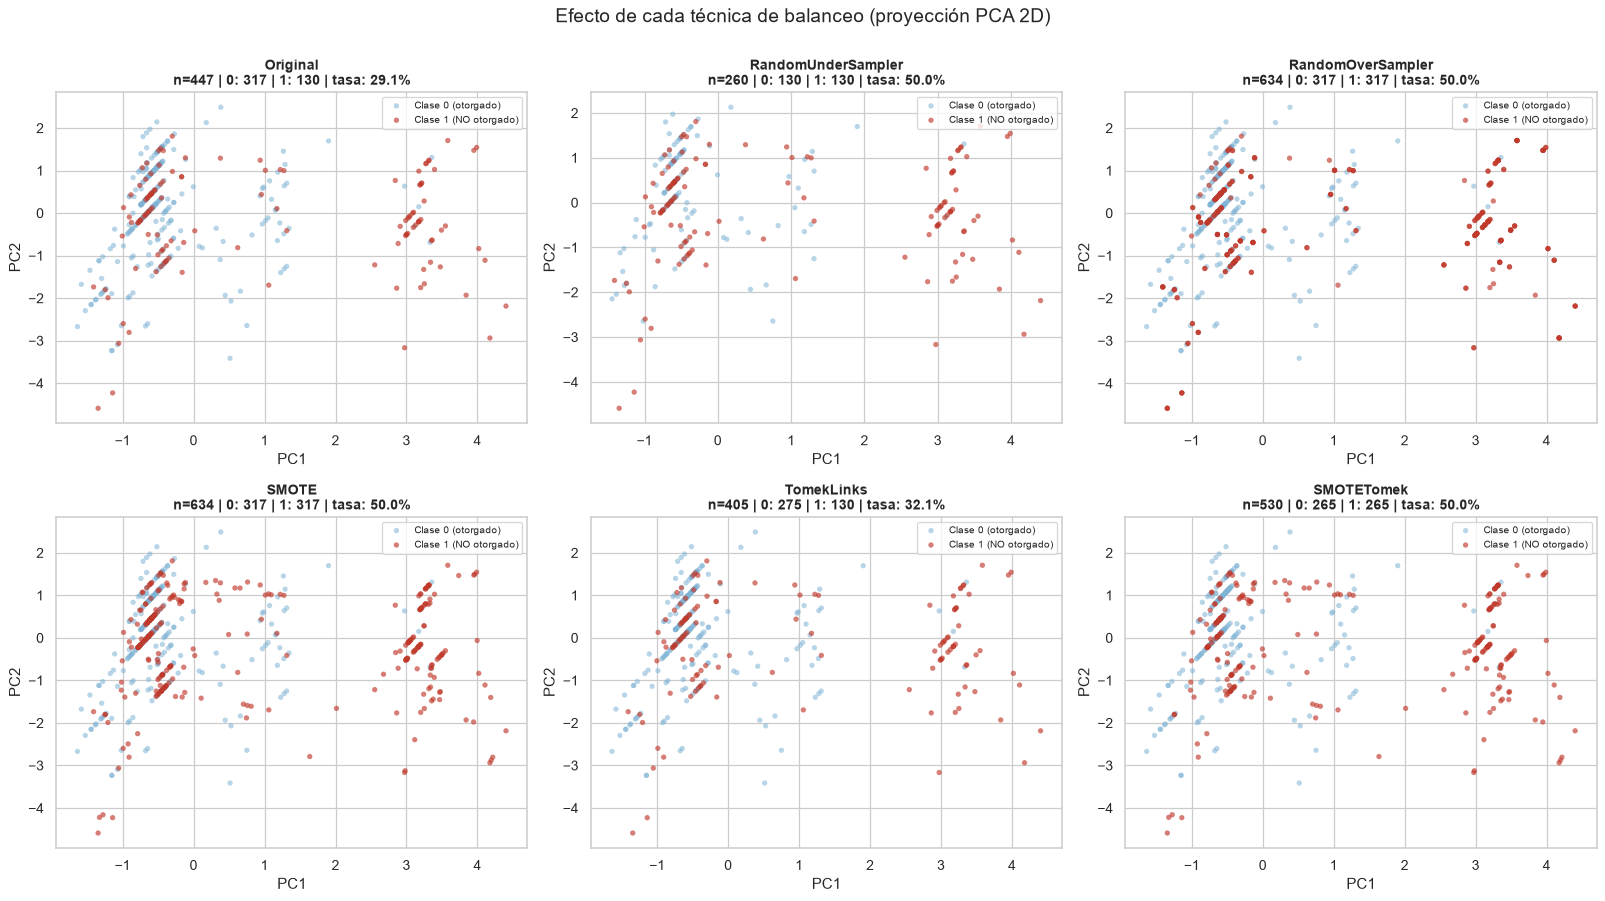

In [8]:
# Proyectamos los datos originales para tenerlos como referencia
Z_original = pca.transform(X_train_scaled)

orden = ['Original', 'RandomUnderSampler', 'RandomOverSampler', 'SMOTE', 'TomekLinks', 'SMOTETomek']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, nombre in zip(axes, orden):
    X_res, y_res = resultados_balanceo[nombre]
    Z = pca.transform(X_res)
    y_res_arr = np.asarray(y_res)

    ax.scatter(Z[y_res_arr == 0, 0], Z[y_res_arr == 0, 1],
               c='#7fb3d5', s=18, alpha=0.55, label='Clase 0 (otorgado)', edgecolors='none')
    ax.scatter(Z[y_res_arr == 1, 0], Z[y_res_arr == 1, 1],
               c='#c0392b', s=18, alpha=0.65, label='Clase 1 (NO otorgado)', edgecolors='none')

    n_0 = int((y_res_arr == 0).sum())
    n_1 = int((y_res_arr == 1).sum())
    ax.set_title(f'{nombre}\nn={len(y_res_arr)} | 0: {n_0} | 1: {n_1} | tasa: {y_res_arr.mean():.1%}',
                 fontsize=11)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(loc='upper right', fontsize=8)

fig.suptitle('Efecto de cada técnica de balanceo (proyección PCA 2D)', fontsize=15, y=1.00)
plt.tight_layout()
plt.show()

El gráfico anterior muestra el resultado, pero no distingue **qué puntos son sintéticos**.
Eso es justo lo que queremos ver de SMOTE. Abajo separamos los originales de los inventados.

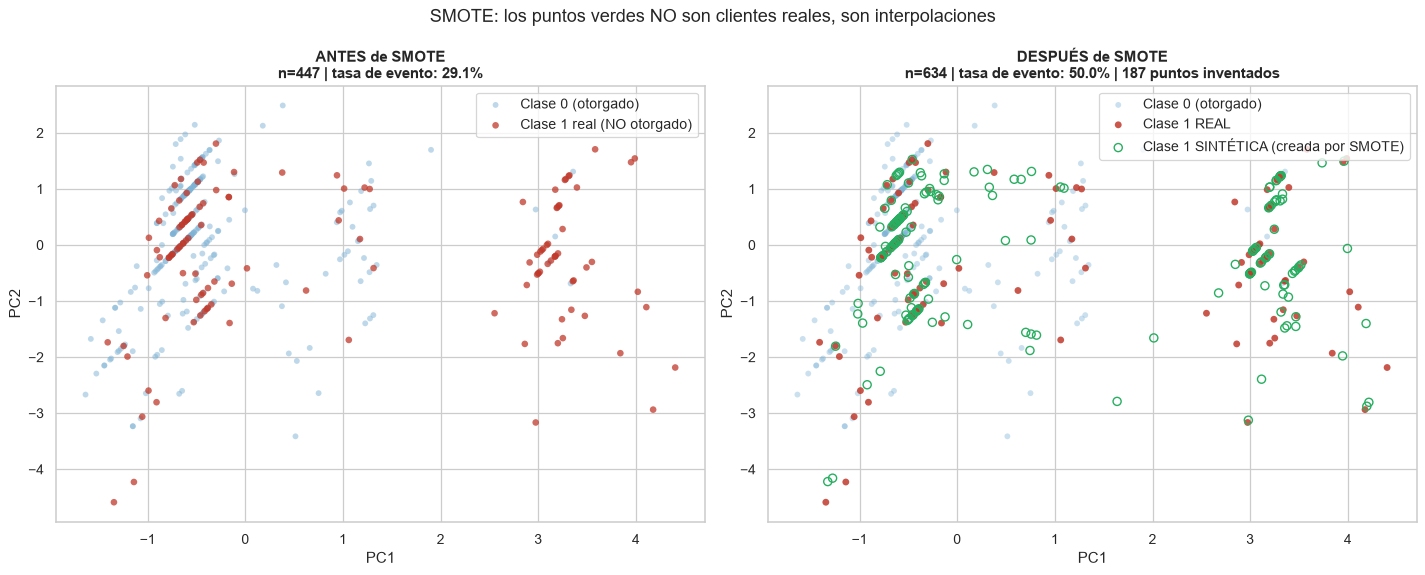

Registros originales : 447
Puntos sintéticos    : 187
Total                : 634

-> El 29.5% de la base de entrenamiento ahora es inventada.


In [9]:
# ---- SMOTE: originales vs. sintéticos ----
X_smote, y_smote = resultados_balanceo['SMOTE']
Z_smote = pca.transform(X_smote)
y_smote_arr = np.asarray(y_smote)

# imbalanced-learn devuelve primero los registros originales y luego los sintéticos
n_orig = len(y_train)
es_sintetico = np.zeros(len(y_smote_arr), dtype=bool)
es_sintetico[n_orig:] = True

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# --- Panel izquierdo: antes ---
ax = axes[0]
ax.scatter(Z_original[y_train.values == 0, 0], Z_original[y_train.values == 0, 1],
           c='#7fb3d5', s=22, alpha=0.5, label='Clase 0 (otorgado)', edgecolors='none')
ax.scatter(Z_original[y_train.values == 1, 0], Z_original[y_train.values == 1, 1],
           c='#c0392b', s=28, alpha=0.75, label='Clase 1 real (NO otorgado)', edgecolors='none')
ax.set_title(f'ANTES de SMOTE\nn={len(y_train)} | tasa de evento: {y_train.mean():.1%}', fontsize=12)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(loc='upper right')

# --- Panel derecho: después, marcando lo sintético ---
ax = axes[1]
ax.scatter(Z_smote[(y_smote_arr == 0), 0], Z_smote[(y_smote_arr == 0), 1],
           c='#7fb3d5', s=22, alpha=0.4, label='Clase 0 (otorgado)', edgecolors='none')
ax.scatter(Z_smote[(y_smote_arr == 1) & (~es_sintetico), 0],
           Z_smote[(y_smote_arr == 1) & (~es_sintetico), 1],
           c='#c0392b', s=30, alpha=0.85, label='Clase 1 REAL', edgecolors='none')
ax.scatter(Z_smote[(y_smote_arr == 1) & (es_sintetico), 0],
           Z_smote[(y_smote_arr == 1) & (es_sintetico), 1],
           facecolors='none', edgecolors='#27ae60', s=42, linewidths=1.1,
           label='Clase 1 SINTÉTICA (creada por SMOTE)')
ax.set_title(f'DESPUÉS de SMOTE\nn={len(y_smote_arr)} | tasa de evento: {y_smote_arr.mean():.1%} | '
             f'{int(es_sintetico.sum())} puntos inventados', fontsize=12)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(loc='upper right')

fig.suptitle('SMOTE: los puntos verdes NO son clientes reales, son interpolaciones', fontsize=14)
plt.tight_layout()
plt.show()

print(f'Registros originales : {n_orig}')
print(f'Puntos sintéticos    : {int(es_sintetico.sum())}')
print(f'Total                : {len(y_smote_arr)}')
print(f'\n-> El {es_sintetico.sum() / len(y_smote_arr):.1%} de la base de entrenamiento ahora es inventada.')

**Qué observar en clase (esto es lo que hay que ver, no solo mirar):**

1. Los puntos verdes **caen en los segmentos de recta entre puntos rojos reales**. Eso es
   literalmente la fórmula $x_{nuevo} = x_i + \lambda(x_{vecino} - x_i)$ dibujada.
2. SMOTE **no crea información nueva ni explora zonas nuevas**: rellena el interior de la
   envolvente convexa de la clase minoritaria. Si un patrón de riesgo no estaba en tus datos,
   SMOTE **no lo va a descubrir**.
3. Mira las zonas donde los puntos rojos y azules **se mezclan**: ahí SMOTE está creando casos
   sintéticos de clase 1 **en territorio de clase 0**. Eso empuja la frontera de decisión
   hacia la clase mayoritaria y es exactamente el origen de los "patrones espurios" del
   material. Es también la razón de ser de SMOTETomek: Tomek limpia después ese desorden.
4. En este dataset las clases están **fuertemente solapadas** — no hay dos nubes separadas.
   Esto ya nos anticipa que ninguna técnica de balanceo va a hacer magia: **el problema aquí
   no es el desbalance, es que las variables tienen poco poder discriminante.**

#### 9.1.4 ¿El balanceo mejora el modelo? Comparación honesta

Todo lo anterior es teoría. La pregunta de negocio es: **¿sirve o no sirve?**

El diseño experimental correcto:
- Entrenamos **la misma** `LogisticRegression` con cada estrategia.
- Evaluamos **todas** en el **MISMO test, SIN balancear**. El test conserva la distribución
  real porque en producción el modelo verá la tasa de evento real de la cartera, no un 50%
  fabricado por nosotros. (La cabecera de la tabla imprime esa tasa: compárala con la columna
  "Tasa train" de cada fila y verás exactamente qué mundo vio cada modelo al entrenar.)
- Incluimos dos alternativas que **no remuestrean nada**: `class_weight='balanced'` y el
  `DummyClassifier` (nuestra línea base: si un modelo no le gana al tonto, no sirve).

In [10]:
from sklearn.linear_model import LogisticRegression

predicciones = {}     # guardamos pred y proba de cada estrategia: los reusa el bootstrap de 9.1.5


def evaluar(nombre, modelo, X_tr, y_tr, X_te, y_te):
    """Entrena en (X_tr, y_tr) y evalúa SIEMPRE en el test original sin balancear."""
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    y_proba = modelo.predict_proba(X_te)[:, 1]
    predicciones[nombre] = {'pred': y_pred, 'proba': y_proba}
    return {
        'Estrategia': nombre,
        'n_train': len(y_tr),
        'Tasa train': f'{np.mean(y_tr):.1%}',
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall': recall_score(y_te, y_pred, zero_division=0),
        'F1': f1_score(y_te, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_te, y_proba),
    }

resultados_modelos = []

# Línea base: el modelo que no aprende nada
resultados_modelos.append(
    evaluar('Dummy (línea base)', DummyClassifier(strategy='most_frequent', random_state=seed),
            X_train_scaled, y_train, X_test_scaled, y_test)
)

# Una regresión logística por cada estrategia de balanceo
for nombre, (X_res, y_res) in resultados_balanceo.items():
    resultados_modelos.append(
        evaluar(nombre if nombre != 'Original' else 'Sin balanceo (Original)',
                LogisticRegression(max_iter=1000, random_state=seed),
                X_res, y_res, X_test_scaled, y_test)
    )

# Alternativa SIN remuestrear: ponderación de clases
resultados_modelos.append(
    evaluar("class_weight='balanced'",
            LogisticRegression(max_iter=1000, random_state=seed, class_weight='balanced'),
            X_train_scaled, y_train, X_test_scaled, y_test)
)

tabla_final = pd.DataFrame(resultados_modelos)

print('COMPARACIÓN DE ESTRATEGIAS — evaluadas en el MISMO TEST SIN BALANCEAR')
print(f'(Test: n={len(y_test)}, tasa de evento real={y_test.mean():.1%})')
print('=' * 104)
print(tabla_final.to_string(index=False,
                            formatters={'Accuracy': '{:.4f}'.format, 'Precision': '{:.4f}'.format,
                                        'Recall': '{:.4f}'.format, 'F1': '{:.4f}'.format,
                                        'ROC-AUC': '{:.4f}'.format}))

COMPARACIÓN DE ESTRATEGIAS — evaluadas en el MISMO TEST SIN BALANCEAR
(Test: n=123, tasa de evento real=31.7%)
             Estrategia  n_train Tasa train Accuracy Precision Recall     F1 ROC-AUC
     Dummy (línea base)      447      29.1%   0.6829    0.0000 0.0000 0.0000  0.5000
Sin balanceo (Original)      447      29.1%   0.8211    1.0000 0.4359 0.6071  0.7167
     RandomUnderSampler      260      50.0%   0.7317    0.5938 0.4872 0.5352  0.7002
      RandomOverSampler      634      50.0%   0.7317    0.5833 0.5385 0.5600  0.7253
                  SMOTE      634      50.0%   0.6829    0.5000 0.5385 0.5185  0.7302
             TomekLinks      405      32.1%   0.8211    1.0000 0.4359 0.6071  0.7170
             SMOTETomek      530      50.0%   0.7073    0.5385 0.5385 0.5385  0.7271
class_weight='balanced'      447      29.1%   0.7561    0.6452 0.5128 0.5714  0.7253


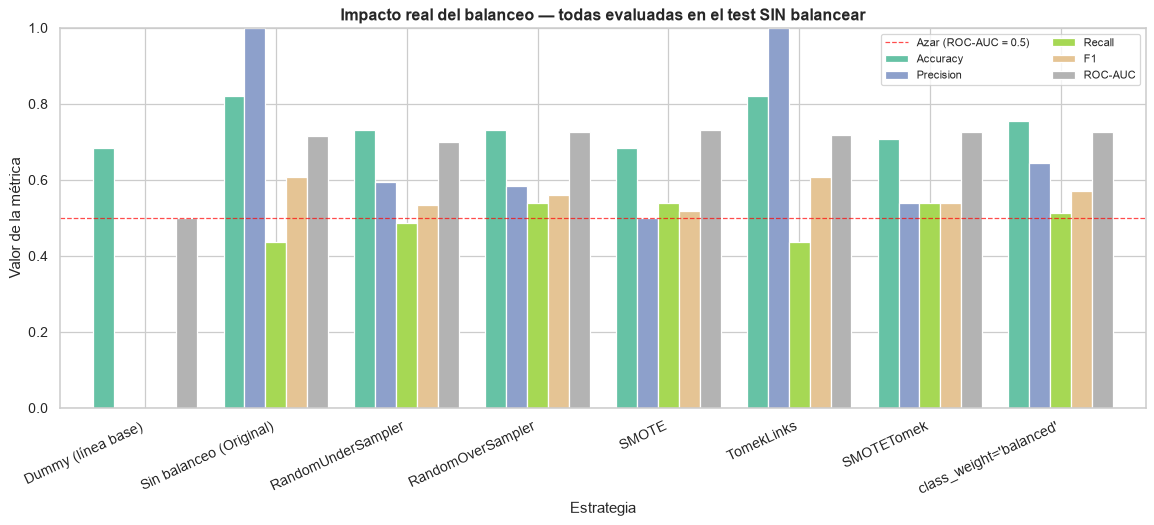

In [11]:
# Visualización de la comparación
metricas_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
tabla_plot = tabla_final.set_index('Estrategia')[metricas_plot]

fig, ax = plt.subplots(figsize=(13, 6))
tabla_plot.plot(kind='bar', ax=ax, width=0.8, colormap='Set2', edgecolor='white')
ax.axhline(0.5, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Azar (ROC-AUC = 0.5)')
ax.set_ylabel('Valor de la métrica')
ax.set_title('Impacto real del balanceo — todas evaluadas en el test SIN balancear', fontsize=13)
ax.set_ylim(0, 1.0)
ax.legend(loc='upper right', ncol=2, fontsize=9)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [12]:
# ---- El trade-off central: ¿qué GANAMOS y qué PERDEMOS al balancear? ----
NOMBRE_BASE = 'Sin balanceo (Original)'
NOMBRE_DUMMY = 'Dummy (línea base)'

base = tabla_final.set_index('Estrategia').loc[NOMBRE_BASE]
metricas = ['Recall', 'Precision', 'F1', 'ROC-AUC']

# Tabla de deltas en PUNTOS PORCENTUALES, calculada — no transcrita.
tabla_delta = (
    tabla_final.set_index('Estrategia')
    .drop(index=[NOMBRE_BASE, NOMBRE_DUMMY])[metricas]
    .sub(base[metricas])
    .astype(float)
    .mul(100)
)

print('CAMBIO vs. NO BALANCEAR (en puntos porcentuales)')
print('=' * 74)
print(tabla_delta.to_string(float_format=lambda v: f'{v:+.1f}'))
print('=' * 74)

# ---- Veredictos DERIVADOS de la tabla, no escritos a mano ----
mejores_f1 = tabla_delta[tabla_delta['F1'] > 0].sort_values('F1', ascending=False)
peores_f1 = tabla_delta[tabla_delta['F1'] < 0].sort_values('F1')

print('\n>> Lectura de la columna F1:')
if len(mejores_f1):
    print(f'   {len(mejores_f1)} de {len(tabla_delta)} técnicas SUPERAN el F1 del modelo sin balancear: '
          f'{", ".join(f"{t} ({d:+.1f})" for t, d in mejores_f1["F1"].items())}.')
    print(f'   La mejor por F1 es {mejores_f1.index[0]} ({mejores_f1["F1"].iloc[0]:+.1f} pp).')
else:
    print('   Ninguna técnica supera el F1 del modelo sin balancear.')
if len(peores_f1):
    print(f'   {len(peores_f1)} lo empeoran, la peor por {abs(peores_f1["F1"].iloc[0]):.1f} pp.')

print('\n>> Lectura de la columna Recall vs. Precision (el intercambio):')
print(f'   El recall se mueve entre {tabla_delta["Recall"].min():+.1f} y {tabla_delta["Recall"].max():+.1f} pp; '
      f'la precisión, entre {tabla_delta["Precision"].min():+.1f} y {tabla_delta["Precision"].max():+.1f} pp.')

print('\n>> Lectura de la columna ROC-AUC: mide la capacidad de ORDENAR (ranking) y es la')
print('   ÚNICA métrica de la tabla que NO depende del umbral. Si el balanceo la mueve poco,')
print('   no mejoró el poder predictivo: solo movió el punto de corte sobre la misma curva.')
print(f'   Aquí el ROC-AUC se mueve entre {tabla_delta["ROC-AUC"].min():+.1f} y '
      f'{tabla_delta["ROC-AUC"].max():+.1f} pp.')

n_eventos_test = int(y_test.sum())
pp_por_cliente = 100 / n_eventos_test          # cuánto mueve el RECALL un solo evento capturado

print(f'\n>> ATENCIÓN, y esto decide todo lo que sigue: el test tiene {len(y_test)} filas y')
print(f'   {n_eventos_test} eventos. El recall es una fracción con {n_eventos_test} en el denominador,')
print(f'   así que detectar UN evento más lo mueve {pp_por_cliente:.1f} pp. No hay valores intermedios:')
print(f'   el recall de este test solo puede tomar {n_eventos_test + 1} valores distintos.')
print(f'   Todas las diferencias de F1 de esta tabla caben entre {tabla_delta["F1"].min():+.1f} y '
      f'{tabla_delta["F1"].max():+.1f} pp,')
print('   o sea: se juegan en un puñado de clientes concretos.')
print('   Una tabla ordenada NO es un resultado: es una hipótesis. En 9.1.5 le exigimos a cada')
print('   una de estas diferencias su intervalo de confianza, y ahí se decide qué sobrevive.')

CAMBIO vs. NO BALANCEAR (en puntos porcentuales)
                         Recall  Precision   F1  ROC-AUC
Estrategia                                              
RandomUnderSampler         +5.1      -40.6 -7.2     -1.6
RandomOverSampler         +10.3      -41.7 -4.7     +0.9
SMOTE                     +10.3      -50.0 -8.9     +1.3
TomekLinks                 +0.0       +0.0 +0.0     +0.0
SMOTETomek                +10.3      -46.2 -6.9     +1.0
class_weight='balanced'    +7.7      -35.5 -3.6     +0.9

>> Lectura de la columna F1:
   Ninguna técnica supera el F1 del modelo sin balancear.
   5 lo empeoran, la peor por 8.9 pp.

>> Lectura de la columna Recall vs. Precision (el intercambio):
   El recall se mueve entre +0.0 y +10.3 pp; la precisión, entre -50.0 y +0.0 pp.

>> Lectura de la columna ROC-AUC: mide la capacidad de ORDENAR (ranking) y es la
   ÚNICA métrica de la tabla que NO depende del umbral. Si el balanceo la mueve poco,
   no mejoró el poder predictivo: solo movió el punto 

#### 9.1.5 ¿Esas diferencias son reales o son ruido?

**Antes de interpretar una sola de las diferencias de la tabla anterior, hay que hacerse la
pregunta que casi nadie se hace: ¿son distinguibles del azar?**

La celda anterior ya lo adelantó: nuestro test es diminuto, y **una diferencia de un par de
puntos de F1 equivale a un puñado de clientes reclasificados**. Cualquier ranking de técnicas
construido sobre ese nivel de ruido es un ejercicio de leer las nubes.

Un punto estimado sin medida de incertidumbre **no es un resultado**. Así que le ponemos un
intervalo de confianza a **cada** diferencia de la tabla, por **bootstrap**: remuestreamos el
test con reemplazo 1,000 veces y miramos la distribución de la diferencia contra el modelo sin
balancear.

**Tres detalles de diseño que importan:**

1. **El bootstrap es *pareado***: en cada repetición, ambos modelos se evalúan sobre **las
   mismas filas remuestreadas**. Así el intervalo mide la diferencia *entre modelos* y no la
   variabilidad del test, que es común a los dos y se cancela. Comparar dos intervalos
   calculados por separado sería un error clásico (y mucho más conservador).
2. **Remuestreamos el test, no el train.** Estamos preguntando por la incertidumbre debida a
   *qué clientes nos tocaron en el test*, con los modelos ya entrenados y fijos.
3. **Medimos ROC-AUC y F1.** El ROC-AUC no depende del umbral; el F1 sí. Son preguntas
   distintas y merecen su propio intervalo cada una.

In [13]:
# ---- Bootstrap PAREADO: IC del ΔROC-AUC y del ΔF1 de cada estrategia vs. sin balancear ----
n_boot = 1000
rng_boot = np.random.default_rng(seed)     # semilla propia: la celda es re-ejecutable

y_test_arr = np.asarray(y_test)
proba_base = predicciones[NOMBRE_BASE]['proba']
pred_base = predicciones[NOMBRE_BASE]['pred']

estrategias_comparadas = [e for e in tabla_delta.index]

# Pre-generamos los índices: TODAS las estrategias comparten los mismos remuestreos (pareado)
indices_boot = []
for _ in range(n_boot):
    idx_b = rng_boot.choice(len(y_test_arr), size=len(y_test_arr), replace=True)
    # Un remuestreo puede quedarse sin una de las clases: ahí el AUC no existe. Lo saltamos.
    if len(np.unique(y_test_arr[idx_b])) < 2:
        continue
    indices_boot.append(idx_b)

dist_boot = {}      # nombre -> {'ROC-AUC': array de diferencias, 'F1': array de diferencias}
filas_ic = []

for nombre in estrategias_comparadas:
    proba_t = predicciones[nombre]['proba']
    pred_t = predicciones[nombre]['pred']
    d_auc = np.empty(len(indices_boot))
    d_f1 = np.empty(len(indices_boot))
    for j, idx_b in enumerate(indices_boot):
        yb = y_test_arr[idx_b]
        d_auc[j] = roc_auc_score(yb, proba_t[idx_b]) - roc_auc_score(yb, proba_base[idx_b])
        d_f1[j] = (f1_score(yb, pred_t[idx_b], zero_division=0)
                   - f1_score(yb, pred_base[idx_b], zero_division=0))
    dist_boot[nombre] = {'ROC-AUC': d_auc, 'F1': d_f1}

    fila = {'Estrategia': nombre,
            # Cuántos clientes del test predice DISTINTO a como los predice el modelo base.
            # Es la traducción física de todas las diferencias de la tabla anterior.
            'Clientes que cambian': int((pred_t != pred_base).sum())}
    for met, d in [('ROC-AUC', d_auc), ('F1', d_f1)]:
        lo, hi = np.percentile(d, [2.5, 97.5])
        cruza = lo <= 0 <= hi
        fila[f'Δ{met}'] = f'{d.mean() * 100:+.1f}'
        fila[f'IC95% Δ{met}'] = f'[{lo * 100:+.1f}, {hi * 100:+.1f}]'
        fila[f'¿{met} distinguible de 0?'] = 'NO' if cruza else 'SÍ'
    filas_ic.append(fila)

tabla_ic = pd.DataFrame(filas_ic).set_index('Estrategia')

print(f'BOOTSTRAP PAREADO vs. "{NOMBRE_BASE}" — {len(indices_boot)} remuestreos válidos del test')
print(f'(Test: n={len(y_test_arr)}, eventos={n_eventos_test}. Todo en puntos porcentuales.)')
print('=' * 118)
print(tabla_ic.to_string())
print('=' * 118)

# ---- Veredicto DERIVADO, no escrito a mano ----
gana_f1 = [n for n in estrategias_comparadas
           if np.percentile(dist_boot[n]['F1'], 2.5) > 0]
gana_auc = [n for n in estrategias_comparadas
            if np.percentile(dist_boot[n]['ROC-AUC'], 2.5) > 0]

print('\n>> ¿Qué sobrevive al intervalo de confianza?')
print(f'   Estrategias con ΔF1 significativamente > 0      : '
      f'{", ".join(gana_f1) if gana_f1 else "NINGUNA"}')
print(f'   Estrategias con ΔROC-AUC significativamente > 0 : '
      f'{", ".join(gana_auc) if gana_auc else "NINGUNA"}')

if len(mejores_f1) and not gana_f1:
    print(f'\n>>> LA LECCIÓN DE LA SECCIÓN, y conviene leerla dos veces:')
    print(f'>>> {len(mejores_f1)} técnica(s) SUPERAN el F1 base EN LA TABLA '
          f'({", ".join(mejores_f1.index)}),')
    print(f'>>> y NINGUNA lo supera de forma distinguible del azar. Las dos cosas son verdad')
    print(f'>>> a la vez, y no se contradicen: "quedó arriba en la tabla" es una observación;')
    print(f'>>> "es mejor" es una AFIRMACIÓN sobre datos futuros, y exige el intervalo.')
    print(f'>>> Todos los IC de arriba cruzan el cero. Con {n_eventos_test} eventos no tenemos')
    print(f'>>> potencia para detectar efectos de este tamaño — así que NO los afirmamos.')
elif gana_f1:
    print(f'\n>>> {", ".join(gana_f1)} mejora(n) el F1 de forma distinguible del azar.')
    print('>>> Con este tamaño de test es un resultado inusual: mirar el ancho del IC antes')
    print('>>> de celebrarlo, y confirmarlo con cross-validation sobre el train.')
else:
    print('\n>>> Ninguna diferencia es distinguible del azar, y ninguna técnica supera')
    print('>>> siquiera al modelo base en la tabla. No hay nada que elegir aquí.')

print('\n>> Y el matiz que NO se puede omitir: "no se detecta diferencia" NO es "son iguales".')
print('   La ausencia de evidencia no es evidencia de ausencia. Lo correcto es decir')
print('   "este test no tiene resolución para distinguirlas", no "da lo mismo cuál uses".')

# ---- Diagnóstico: ¿por qué los intervalos son tan anchos? Porque cambian poquísimos clientes ----
print('\n>> DE DÓNDE SALE TODO ESTO: mira la columna "Clientes que cambian".')
for nombre in estrategias_comparadas:
    n_cambian = int((predicciones[nombre]['pred'] != pred_base).sum())
    print(f'   {nombre:<24}: reclasifica {n_cambian:>3} de {len(y_test_arr)} clientes del test '
          f'({n_cambian / len(y_test_arr):.1%})')
print('   Toda la tabla comparativa —cada décima de F1, cada punto de AUC— se juega en esos')
print('   puñados de clientes. Por eso los intervalos son tan anchos: no hay más información')
print('   disponible. No es un defecto del bootstrap; es el tamaño real de nuestra evidencia.')

# ---- El caso raro que merece nombrarse: distribuciones con un átomo en cero ----
n_test = len(y_test_arr)
for nombre in estrategias_comparadas:
    d = dist_boot[nombre]['F1']
    p_cero = (d == 0).mean()
    if p_cero <= 0.10:
        continue
    n_cambian = int((predicciones[nombre]['pred'] != pred_base).sum())
    # P(un cliente concreto NO aparezca en un remuestreo bootstrap) = (1 - 1/n)^n -> 1/e
    p_fuera = (1 - 1 / n_test) ** n_test
    print(f'\n>> CASO CURIOSO, y vale la pena pararse aquí — {nombre}:')
    print(f'   ΔF1 = {d.mean() * 100:+.1f} pp en la tabla, pero en el {p_cero:.0%} de los remuestreos su')
    print(f'   ΔF1 es EXACTAMENTE cero, y es negativo en el {(d < 0).mean():.0%} de ellos.')
    print(f'   Su IC95% arranca justo EN el cero y lo toca: NO es distinguible del azar.')
    print(f'\n   ¿De dónde sale ese {p_cero:.0%}? De que esta técnica reclasifica exactamente')
    print(f'   {n_cambian} cliente(s) del test. En los remuestreos donde ese/esos cliente(s) no')
    print(f'   salen sorteados, los dos modelos predicen EXACTAMENTE lo mismo y la diferencia')
    print(f'   no es "pequeña": no existe.')
    if n_cambian == 1:
        print(f'   Y el número no es casualidad: la probabilidad de que un cliente concreto NO')
        print(f'   entre en un remuestreo bootstrap es (1 - 1/{n_test})^{n_test} = {p_fuera:.1%} ≈ 1/e.')
        print(f'   Observamos {p_cero:.0%}. Es el mismo 36.8% del out-of-bag de un Random Forest,')
        print(f'   apareciendo aquí sin que lo invitáramos. La teoría no se toma vacaciones.')
    print(f'\n   MORALEJA: un IC no se lee solo por sus extremos. Cuando el bootstrap te devuelve')
    print(f'   un pico de probabilidad EN el cero, la lectura correcta no es "casi gana": es')
    print(f'   "casi siempre no hace nada, y todo su ΔF1 depende de {n_cambian} cliente(s)".')
    print(f'   Un efecto que se sostiene sobre {n_cambian} observación(es) no es un efecto:')
    print(f'   es una anécdota con decimales.')

BOOTSTRAP PAREADO vs. "Sin balanceo (Original)" — 1000 remuestreos válidos del test
(Test: n=123, eventos=39. Todo en puntos porcentuales.)
                         Clientes que cambian ΔROC-AUC IC95% ΔROC-AUC ¿ROC-AUC distinguible de 0?   ΔF1      IC95% ΔF1 ¿F1 distinguible de 0?
Estrategia                                                                                                                                   
RandomUnderSampler                         15     -1.7   [-4.3, +0.4]                          NO  -7.1  [-16.2, +1.8]                     NO
RandomOverSampler                          19     +0.8   [-1.9, +3.6]                          NO  -4.7  [-15.5, +6.8]                     NO
SMOTE                                      25     +1.3   [-0.1, +3.0]                          NO  -8.7  [-20.4, +3.1]                     NO
TomekLinks                                  0     +0.0   [-0.6, +0.6]                          NO  +0.0   [+0.0, +0.0]                     NO
SMOTETom

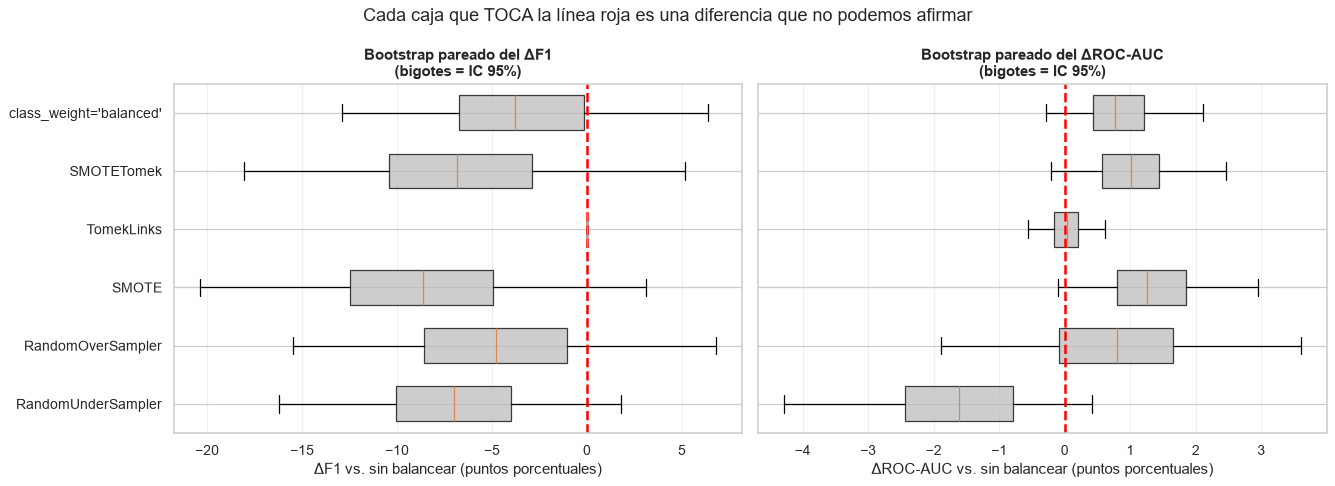

In [14]:
# Visualización: la distribución bootstrap del ΔF1 de cada estrategia
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

for ax, met in zip(axes, ['F1', 'ROC-AUC']):
    posiciones = np.arange(len(estrategias_comparadas))
    datos = [dist_boot[n][met] * 100 for n in estrategias_comparadas]
    bp = ax.boxplot(datos, positions=posiciones, vert=False, widths=0.6,
                    patch_artist=True, showfliers=False, whis=(2.5, 97.5))
    for caja, nombre in zip(bp['boxes'], estrategias_comparadas):
        lo, hi = np.percentile(dist_boot[nombre][met], [2.5, 97.5])
        # Verde solo si el IC95% NO cruza el cero
        caja.set_facecolor('#1b9e77' if not (lo <= 0 <= hi) else '#bdbdbd')
        caja.set_alpha(0.75)
    ax.axvline(0, color='red', linestyle='--', linewidth=2)
    ax.set_yticks(posiciones)
    ax.set_yticklabels(estrategias_comparadas)
    ax.set_xlabel(f'Δ{met} vs. sin balancear (puntos porcentuales)')
    ax.set_title(f'Bootstrap pareado del Δ{met}\n(bigotes = IC 95%)', fontsize=12)
    ax.grid(axis='x', alpha=0.3)

fig.suptitle('Cada caja que TOCA la línea roja es una diferencia que no podemos afirmar',
             fontsize=14)
plt.tight_layout()
plt.show()

**Esta celda es la más importante de la sección, metodológicamente.**

Mira el gráfico: **cada caja que toca la línea roja del cero es una diferencia que no podemos
afirmar.** No importa lo bonito que se vea su número en la tabla comparativa.

Y aquí está el punto que hay que entender de verdad, porque es el que separa a un analista de
alguien que solo ordena tablas:

> **"Quedó arriba en la tabla" y "es mejor" son dos afirmaciones distintas.**
> La primera es una **observación** sobre los clientes concretos que cayeron en este test: es
> un hecho, y no se discute.
> La segunda es una **predicción** sobre clientes que todavía no hemos visto. Solo la segunda
> sirve para decidir, y solo la segunda necesita un intervalo de confianza.

Las dos pueden ser verdad a la vez sin contradecirse. Que una técnica encabece la tabla y que
no podamos afirmar que sea mejor **no es una paradoja**: es lo que ocurre siempre que el
tamaño del efecto es del orden del ruido. La tabla ordena; el intervalo dice si el orden
significa algo.

Y ojo con el error simétrico, que es igual de grave: "no encontramos diferencia" **no es lo
mismo que** "demostramos que son iguales". Con este puñado de eventos en el test **no tenemos
potencia estadística** para detectar diferencias pequeñas. La ausencia de evidencia no es
evidencia de ausencia.

**La lección práctica que hay que llevarse a los proyectos:** cuando alguien te presente una
tabla de 6 técnicas ordenadas por AUC y te diga "SMOTE ganó por 0.004", la respuesta correcta
es **"¿cuál es el intervalo de confianza?"**. Casi siempre esas diferencias caben dentro del
ruido, y elegir la técnica ganadora por el tercer decimal es **sobreajustar al test**: estás
usando el test para decidir, y a partir de ese momento deja de ser un test.

> 🎓 **Si el IC cruza el cero, la decisión no la toma la estadística.** La toma el costo: elige
> la técnica más simple, más barata de mantener y que no distorsione tus probabilidades. Con
> los datos empatados, "no tocar los datos" es la opción que gana por default.

### 9.3 Conclusión honesta sobre este dataset

Una sección que se llama "conclusión honesta" tiene una obligación incómoda: **la conclusión
la escriben los números, no el guion.** Así que la celda de abajo **no está escrita a mano**.
Lee las tablas que acabamos de calcular y redacta el veredicto a partir de ellas. Si mañana
cambia el split y el resultado se da vuelta, el texto se da vuelta solo.

Eso no es una comodidad técnica: es la única forma de que "no vamos a maquillar el resultado"
sea verificable en vez de ser una promesa. **La trampa más fácil de este oficio es escribir la
conclusión antes de mirar la tabla, y después leer la tabla buscando confirmarla.** Es el sesgo
de confirmación, y no perdona a nadie por saber cómo se llama.

In [15]:
# ---- El veredicto se DERIVA de las tablas. Ni un número escrito a mano. ----
tasa_evento_train = y_train.mean()
ratio_desbalance = (y_train == 0).sum() / (y_train == 1).sum()
ES_EVENTO_RARO = tasa_evento_train <= 0.10          # umbral del propio material: 0.1% - 10%

n_tomek = len(y_train) - len(resultados_balanceo['TomekLinks'][1])
delta_tomek = tabla_delta.loc['TomekLinks']

print('=' * 78)
print('  CONCLUSIÓN SOBRE ESTE DATASET — generada a partir de las tablas anteriores')
print('=' * 78)

# --- 1. ¿Hay siquiera un problema de evento raro? ---
print('\n1. ¿TENEMOS UN PROBLEMA DE EVENTO RARO?')
print(f'   Tasa de evento en train: {tasa_evento_train:.1%}. Ratio mayoritaria:minoritaria = '
      f'{ratio_desbalance:.2f} : 1')
if ES_EVENTO_RARO:
    print('   SÍ: la tasa cae dentro del rango 0.1%-10% que el material define como evento raro.')
else:
    print(f'   NO. {tasa_evento_train:.1%} está MUY por encima del rango 0.1%-10% que el material')
    print('   define como evento raro. Aplicar balanceo aquí es resolver un problema que no')
    print('   tenemos: el modelo sin balancear ya predice ambas clases sin dificultad.')

# --- 2. ¿Qué dice la tabla, y qué sobrevive al intervalo? ---
print('\n2. ¿MEJORÓ EL BALANCEO EL MODELO? (la tabla vs. el intervalo de confianza)')
if len(mejores_f1):
    print(f'   EN LA TABLA: {len(mejores_f1)} de {len(tabla_delta)} técnicas superan el F1 base -> '
          f'{", ".join(f"{t} ({d:+.1f})" for t, d in mejores_f1["F1"].items())}.')
else:
    print('   EN LA TABLA: ninguna técnica supera el F1 del modelo sin balancear.')
if gana_f1 or gana_auc:
    print(f'   CON INTERVALO: sobreviven -> F1: {", ".join(gana_f1) or "ninguna"} | '
          f'ROC-AUC: {", ".join(gana_auc) or "ninguna"}.')
    print('   Ahí sí hay algo que discutir. Confírmalo con cross-validation antes de moverlo.')
else:
    print('   CON INTERVALO: NINGUNA. Todos los IC95% del bootstrap pareado cruzan el cero.')
    print('   Conclusión defendible: el balanceo NO compró poder predictivo. Lo que hizo fue')
    print('   MOVER EL PUNTO DE OPERACIÓN sobre la misma curva ROC.')
    if len(mejores_f1):
        print(f'   Y no, no nos contradecimos: "{mejores_f1.index[0]} encabeza la tabla" y "no')
        print('   podemos afirmar que sea mejor" son verdad a la vez. La primera describe a los')
        print(f'   {len(y_test)} clientes del test; la segunda es lo único que se puede prometer')
        print('   sobre los clientes que vendrán. Solo la segunda sirve para decidir.')

# --- 3. El intercambio real ---
print('\n3. ¿QUÉ SE INTERCAMBIÓ REALMENTE?')
print(f'   Recall   : {tabla_delta["Recall"].min():+.1f} a {tabla_delta["Recall"].max():+.1f} pp')
print(f'   Precision: {tabla_delta["Precision"].min():+.1f} a {tabla_delta["Precision"].max():+.1f} pp')
print(f'   ROC-AUC  : {tabla_delta["ROC-AUC"].min():+.1f} a {tabla_delta["ROC-AUC"].max():+.1f} pp')
print('   Al entrenar al 50/50 el modelo infla sus probabilidades, cruza el 0.5 más seguido y')
print('   marca más clientes como riesgosos: sube el recall y cae la precisión. Con el ROC-AUC')
print('   prácticamente quieto, eso NO es un salto a una curva mejor: es un desplazamiento')
print('   sobre la MISMA curva. El modelo no aprendió nada nuevo, solo se volvió más alarmista.')

# --- 4. TomekLinks: el caso interesante ---
tomek_cambia = int((predicciones['TomekLinks']['pred'] != pred_base).sum())
print('\n4. EL CASO TomekLinks — el más instructivo de la tabla')
print(f'   Eliminó {n_tomek} registros de la frontera ({n_tomek / len(y_train):.1%} del train) y quedó en '
      f'ΔF1 {delta_tomek["F1"]:+.1f}, ΔRecall {delta_tomek["Recall"]:+.1f},')
print(f'   ΔPrecision {delta_tomek["Precision"]:+.1f}, ΔROC-AUC {delta_tomek["ROC-AUC"]:+.1f} pp.')
if delta_tomek['Precision'] > 0 and delta_tomek['Precision'] == tabla_delta['Precision'].max():
    print('   Es la ÚNICA técnica que MEJORA la precisión en vez de destruirla — y tiene sentido:')
    print('   no inventa ni duplica nada, solo limpia. Tampoco balancea (no es su trabajo).')
print(f'\n   Pero aquí está lo que hay que ver: borrar {n_tomek} registros del train cambió la')
print(f'   predicción de {tomek_cambia} cliente(s) del test. TODO su ΔF1 {delta_tomek["F1"]:+.1f} sale de ahí.')
print('   Dos lecturas, ambas ciertas:')
print('   (a) Sobre la frontera: que borrar los puntos limítrofes mueva casi nada confirma que')
print('       la decisión la define una variable fuerte (Credit_History domina), no esos puntos.')
print(f'   (b) Sobre el método: una técnica puede empatar en lo alto de la tabla apoyándose en')
print(f'       {tomek_cambia} cliente(s). Si eso te parece poca base para una decisión, es porque')
print('       lo es — y es exactamente lo que el intervalo de confianza acaba de decirnos.')

# --- 5. La alternativa barata ---
print('\n5. EL COROLARIO INCÓMODO')
print('   El mismo efecto (más alertas, menos precisión) se consigue BAJANDO EL UMBRAL del')
print('   modelo sin balancear: sin inventar un dato, sin tirar un registro y sin romper la')
print('   calibración. Lo comprobamos abajo. Aquí, el balanceo es una forma cara, indirecta')
print('   y no auditable de mover un umbral.')

# --- 6. El techo real ---
print('\n6. EL TECHO NO ES EL DESBALANCE: ES LA SEÑAL')
print(f'   ROC-AUC del mejor modelo de la tabla: {tabla_final["ROC-AUC"].max():.4f}. Lo vimos en el')
print('   PCA: las clases están fuertemente solapadas. Ninguna técnica de remuestreo crea')
print('   información que no está en los datos. ¿Quieres más AUC? Mejores VARIABLES, no más')
print('   filas sintéticas.')
print('=' * 78)

  CONCLUSIÓN SOBRE ESTE DATASET — generada a partir de las tablas anteriores

1. ¿TENEMOS UN PROBLEMA DE EVENTO RARO?
   Tasa de evento en train: 29.1%. Ratio mayoritaria:minoritaria = 2.44 : 1
   NO. 29.1% está MUY por encima del rango 0.1%-10% que el material
   define como evento raro. Aplicar balanceo aquí es resolver un problema que no
   tenemos: el modelo sin balancear ya predice ambas clases sin dificultad.

2. ¿MEJORÓ EL BALANCEO EL MODELO? (la tabla vs. el intervalo de confianza)
   EN LA TABLA: ninguna técnica supera el F1 del modelo sin balancear.
   CON INTERVALO: NINGUNA. Todos los IC95% del bootstrap pareado cruzan el cero.
   Conclusión defendible: el balanceo NO compró poder predictivo. Lo que hizo fue
   MOVER EL PUNTO DE OPERACIÓN sobre la misma curva ROC.

3. ¿QUÉ SE INTERCAMBIÓ REALMENTE?
   Recall   : +0.0 a +10.3 pp
   Precision: -50.0 a +0.0 pp
   ROC-AUC  : -1.6 a +1.3 pp
   Al entrenar al 50/50 el modelo infla sus probabilidades, cruza el 0.5 más seguido y
   

**Lo importante metodológicamente** — y esto sí no depende de qué números salgan:

Llegamos a una conclusión defendible porque hicimos tres cosas que se omiten sistemáticamente:

1. **Medimos en el test sin balancear.** El test conserva la realidad o no mide nada.
2. **Comparamos contra una línea base**: el modelo sin balancear y el `Dummy`. Una métrica sin
   línea base no se puede interpretar.
3. **Le pusimos un intervalo de confianza a cada diferencia.** Sin esto, ordenar la tabla y
   coronar a la primera fila es leer las nubes.

Si solo hubiéramos entrenado con SMOTE y reportado su recall y su AUC, el número se vería
perfectamente respetable — y habría ocultado por completo el precio pagado en precisión y el
hecho de que la diferencia no es distinguible del azar.

> **Regla práctica:** el balanceo empieza a aportar valor real cuando el evento baja de ~5-10%,
> y sobre todo cuando el algoritmo directamente **no converge** o **nunca predice** la clase
> minoritaria. Antes de eso, **primero prueba `class_weight='balanced'` y ajustar el umbral.**
> Son más baratos, no distorsionan los datos y muchas veces rinden igual o mejor.

**Y ojo con la generalización inversa:** lo que este experimento muestra vale **para este
dataset, a esta tasa de evento y con este tamaño de test**. No es "SMOTE es malo". Es que
**el balanceo es una herramienta condicional, y la condición se verifica antes, no se asume**.
A un 0.5% de fraude, con decenas de miles de casos y potencia de sobra para detectar
diferencias, la historia puede ser completamente distinta — y el método para averiguarlo
sería exactamente el mismo que acabamos de aplicar.

### 9.4 Advertencias críticas (lo que sale mal en la vida real)

Esta sección vale más que todo el código anterior. Son los errores que aparecen en
producción, en auditorías y en comités de riesgo.

---

#### ⚠️ 1. El balanceo se aplica SOLO a TRAIN. JAMÁS a TEST.

El test debe mantener la **distribución real de la población**, porque su único trabajo es
estimar cómo se comportará el modelo en producción. Si balanceas el test al 50/50, tus
métricas describen un mundo que no existe.

```python
# MAL — métricas infladas que no significan nada
X_res, y_res = SMOTE().fit_resample(X, y)
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res)

# BIEN — el test conserva la realidad
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y)
X_train_res, y_train_res = SMOTE().fit_resample(X_train, y_train)
```

---

#### ⚠️ 2. Aplicar SMOTE ANTES del split es leakage grave.

Y es el error más frecuente de todos. La mecánica del daño: SMOTE crea un punto sintético
**interpolando entre dos registros reales**. Si lo haces antes del split, un punto sintético
generado a partir del cliente A puede caer en **train** mientras el cliente A original cae en
**test**. El modelo entrena con una versión "casi idéntica" del caso que después va a evaluar.

Resultado: métricas de validación **espectaculares** (AUC de 0.95) y un modelo que se derrumba
en producción. La regla es simple y absoluta: **primero el split, después el resampling.**
Y en validación cruzada, el resampling va **dentro de cada fold** — usa
`imblearn.pipeline.Pipeline`, que lo garantiza automáticamente (el `Pipeline` de sklearn **no**
sabe hacer esto correctamente con samplers).

```python
from imblearn.pipeline import Pipeline as ImbPipeline

# El resampling ocurre DENTRO de cada fold de la CV. Esto es lo correcto.
pipe = ImbPipeline([
    ('smote', SMOTE(random_state=seed)),
    ('modelo', LogisticRegression(max_iter=1000)),
])
# cross_val_score(pipe, X_train, y_train, cv=5, scoring='roc_auc')
```

---

#### ⚠️ 3. El ORDEN importa: SMOTE va DESPUÉS de imputar y escalar.

SMOTE calcula **vecinos más cercanos**, o sea **distancias euclidianas**. De ahí salen tres
requisitos no negociables:

- **Datos completos**: KNN no puede calcular distancias con `NaN` → imputa primero.
- **Datos escalados**: sin escalar, `ApplicantIncome` (0–81,000) domina por completo la
  distancia frente a `Credit_History` (0–1). Los "vecinos" serían simplemente los de ingreso
  parecido, y los sintéticos, ruido.
- **Datos numéricos**: interpolar una dummy da 0.37 → "casado en un 37%". Sin sentido.
  Para categóricas usa **`SMOTENC`** (mixtas) o **`SMOTEN`** (todas categóricas).

**Orden correcto:** `split → imputar → encodear → escalar → SMOTE → entrenar`

**Sutileza importante:** la imputación y el escalador se ajustan (`fit`) **solo con train** y
se aplican (`transform`) a test. Ajustar el escalador con todo el dataset también es leakage
(más sutil, pero leakage al fin).

---

#### ⚠️ 4. El balanceo DISTORSIONA las probabilidades predichas.

Esta es la advertencia que casi nunca se dice en clase, y la que más cuesta en banca.

Al entrenar con 50/50 cuando la realidad de la cartera es otra, le estás **mintiendo al modelo
sobre la probabilidad a priori**. El modelo devuelve probabilidades **sistemáticamente
infladas**: te promete más riesgo del que ocurre. El **ranking** se conserva (por eso el
ROC-AUC casi no cambia), pero el **nivel** está roto. La celda de abajo mide exactamente
cuánto, comparando la probabilidad media predicha contra la tasa de evento real del test.

¿Cuándo importa? **Siempre que uses el score como probabilidad y no solo como ranking:**
- Cálculo de **pérdida esperada**: $EL = PD \times LGD \times EAD$. Si la PD está inflada,
  tu provisión está mal calculada.
- **Pricing** basado en riesgo → tasas de interés incorrectas.
- **Modelos IFRS 9 / Basilea** → el regulador exige PD calibradas. No es opcional.
- Multiplicar o componer scores de varios modelos.

**La corrección del intercepto (oversampling correction).** Para la regresión logística existe
una corrección analítica exacta (King & Zeng, 2001): el remuestreo afecta **únicamente al
intercepto**, no a los coeficientes de las variables. Se corrige así:

$$\beta_0^{corregido} = \beta_0^{muestra} - \ln\left(\frac{p_1 / p_0}{\pi_1 / \pi_0}\right)$$

donde $p$ son las proporciones **en la muestra balanceada** y $\pi$ las de la **población real**.
Lo demostramos abajo con números.

In [16]:
# ---- DEMOSTRACIÓN: el balanceo rompe la calibración, y cómo corregirlo ----
from sklearn.calibration import calibration_curve

modelo_sin_bal = LogisticRegression(max_iter=1000, random_state=seed).fit(X_train_scaled, y_train)
X_sm, y_sm = resultados_balanceo['SMOTE']
modelo_con_smote = LogisticRegression(max_iter=1000, random_state=seed).fit(X_sm, y_sm)

proba_sin_bal = modelo_sin_bal.predict_proba(X_test_scaled)[:, 1]
proba_con_smote = modelo_con_smote.predict_proba(X_test_scaled)[:, 1]

TOL_CALIBRACION = 0.02        # a partir de aquí decimos que el nivel está desviado


def etiqueta_calibracion(proba, y_real):
    """Etiqueta el sesgo de nivel del score. El veredicto lo decide el número, no el guion."""
    sesgo = proba.mean() - y_real.mean()
    if sesgo > TOL_CALIBRACION:
        return sesgo, 'INFLADA (promete más riesgo del que ocurre)'
    if sesgo < -TOL_CALIBRACION:
        return sesgo, 'SUBESTIMADA (promete menos riesgo del que ocurre)'
    return sesgo, 'coincide con la realidad'


print('¿ESTÁN CALIBRADAS LAS PROBABILIDADES? (test sin balancear)')
print('=' * 72)
print(f'Tasa de evento REAL en el test          : {y_test.mean():.4f}')
for proba, nombre in [(proba_sin_bal, 'SIN balanceo'), (proba_con_smote, 'CON SMOTE')]:
    sesgo, etiqueta = etiqueta_calibracion(proba, y_test)
    print(f'Probabilidad media predicha {nombre:<12}: {proba.mean():.4f}  <-- {etiqueta}')

sesgo_smote, _ = etiqueta_calibracion(proba_con_smote, y_test)
print(f'\nSesgo de calibración por usar SMOTE: {sesgo_smote:+.4f} '
      f'({(proba_con_smote.mean() / y_test.mean() - 1) * 100:+.1f}% relativo)')

# ---- Corrección del intercepto (King & Zeng, 2001) ----
pi_1 = y_train.mean()            # proporción real de evento en la población
pi_0 = 1 - pi_1
p_1 = float(np.mean(y_sm))       # proporción de evento en la muestra balanceada
p_0 = 1 - p_1

ajuste = np.log((p_1 / p_0) / (pi_1 / pi_0))

modelo_corregido = LogisticRegression(max_iter=1000, random_state=seed).fit(X_sm, y_sm)
modelo_corregido.intercept_ = modelo_corregido.intercept_ - ajuste
proba_corregida = modelo_corregido.predict_proba(X_test_scaled)[:, 1]

print(f'\n--- Corrección del intercepto ---')
print(f'Proporción de evento en la muestra balanceada (p1): {p_1:.4f}')
print(f'Proporción de evento en la población real     (π1): {pi_1:.4f}')
print(f'Ajuste a restar del intercepto: ln((p1/p0)/(π1/π0)) = {ajuste:.4f}')
print(f'\nProbabilidad media tras la corrección: {proba_corregida.mean():.4f}  '
      f'(real: {y_test.mean():.4f})')
print(f'Sesgo residual: {proba_corregida.mean() - y_test.mean():+.4f}')

# El ranking NO cambia: el AUC es idéntico antes y después de corregir
auc_smote_crudo = roc_auc_score(y_test, proba_con_smote)
auc_smote_corr = roc_auc_score(y_test, proba_corregida)
print(f'\nROC-AUC con SMOTE sin corregir : {auc_smote_crudo:.4f}')
print(f'ROC-AUC con SMOTE corregido    : {auc_smote_corr:.4f}')
print(f'Diferencia: {auc_smote_corr - auc_smote_crudo:+.6f}')
print('-> La corrección arregla el NIVEL de la probabilidad, NO el orden de los clientes.')
print('   Y no es casualidad: restar una constante del intercepto es una transformación')
print('   MONÓTONA del score. No puede reordenar a nadie, así que el AUC no puede cambiar.')
print('   Es una identidad matemática, no un hallazgo empírico.')
print()
print('   OJO con el error de lectura fácil aquí: que estos dos AUC sean iguales NO dice')
print('   nada sobre si el balanceo sirve o no. Compara SMOTE contra SMOTE. La pregunta')
print('   "¿el balanceo mejora el poder discriminante?" es SMOTE contra SIN BALANCEAR, y esa')
print('   ya la respondimos donde correspondía: con el bootstrap pareado de 9.1.5.')

¿ESTÁN CALIBRADAS LAS PROBABILIDADES? (test sin balancear)
Tasa de evento REAL en el test          : 0.3171
Probabilidad media predicha SIN balanceo: 0.2977  <-- coincide con la realidad
Probabilidad media predicha CON SMOTE   : 0.4477  <-- INFLADA (promete más riesgo del que ocurre)

Sesgo de calibración por usar SMOTE: +0.1306 (+41.2% relativo)

--- Corrección del intercepto ---
Proporción de evento en la muestra balanceada (p1): 0.5000
Proporción de evento en la población real     (π1): 0.2908
Ajuste a restar del intercepto: ln((p1/p0)/(π1/π0)) = 0.8914

Probabilidad media tras la corrección: 0.2999  (real: 0.3171)
Sesgo residual: -0.0172

ROC-AUC con SMOTE sin corregir : 0.7302
ROC-AUC con SMOTE corregido    : 0.7302
Diferencia: +0.000000
-> La corrección arregla el NIVEL de la probabilidad, NO el orden de los clientes.
   Y no es casualidad: restar una constante del intercepto es una transformación
   MONÓTONA del score. No puede reordenar a nadie, así que el AUC no puede cambiar.

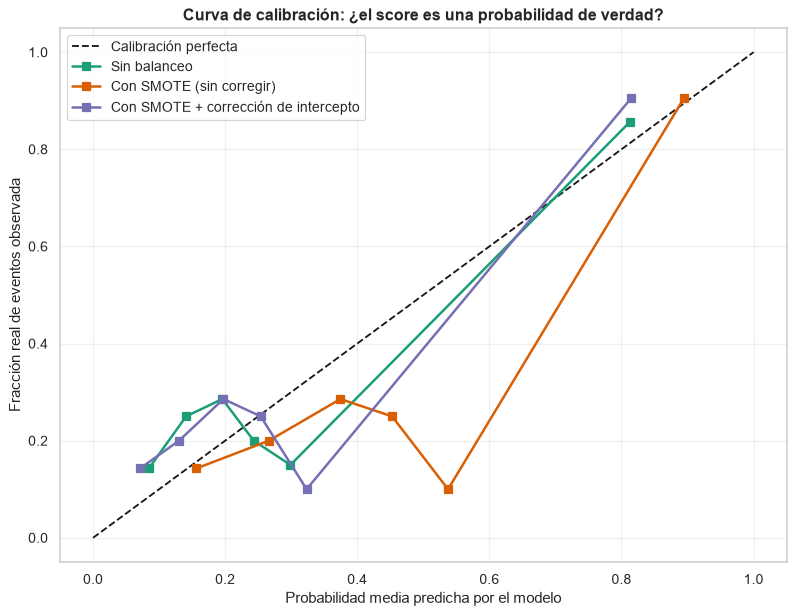

Interpretación: si un modelo bien calibrado dice "0.3", entonces de cada 100 clientes
con ese score, ~30 deberían resultar impagos: la curva sigue la diagonal.

  Sin balanceo                : sesgo medio -0.0193 -> sigue la diagonal -> el score SÍ se puede leer como probabilidad
  Con SMOTE (sin corregir)    : sesgo medio +0.1306 -> cae POR DEBAJO de la diagonal -> promete MÁS riesgo del que ocurre (PD inflada)
  Con SMOTE + corrección      : sesgo medio -0.0172 -> sigue la diagonal -> el score SÍ se puede leer como probabilidad


In [17]:
# Curvas de calibración
fig, ax = plt.subplots(figsize=(9, 7))

ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Calibración perfecta')

for proba, nombre, color in [
    (proba_sin_bal, 'Sin balanceo', '#1b9e77'),
    (proba_con_smote, 'Con SMOTE (sin corregir)', '#d95f02'),
    (proba_corregida, 'Con SMOTE + corrección de intercepto', '#7570b3'),
]:
    frac_pos, media_pred = calibration_curve(y_test, proba, n_bins=6, strategy='quantile')
    ax.plot(media_pred, frac_pos, 's-', label=nombre, color=color, linewidth=2, markersize=7)

ax.set_xlabel('Probabilidad media predicha por el modelo')
ax.set_ylabel('Fracción real de eventos observada')
ax.set_title('Curva de calibración: ¿el score es una probabilidad de verdad?', fontsize=13)
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Interpretación: si un modelo bien calibrado dice "0.3", entonces de cada 100 clientes')
print('con ese score, ~30 deberían resultar impagos: la curva sigue la diagonal.')
print()
for proba, nombre in [(proba_sin_bal, 'Sin balanceo'),
                      (proba_con_smote, 'Con SMOTE (sin corregir)'),
                      (proba_corregida, 'Con SMOTE + corrección')]:
    sesgo = proba.mean() - y_test.mean()
    if sesgo > 0.02:
        lectura = 'cae POR DEBAJO de la diagonal -> promete MÁS riesgo del que ocurre (PD inflada)'
    elif sesgo < -0.02:
        lectura = 'cae POR ENCIMA de la diagonal -> promete MENOS riesgo del que ocurre (PD subestimada)'
    else:
        lectura = 'sigue la diagonal -> el score SÍ se puede leer como probabilidad'
    print(f'  {nombre:<28}: sesgo medio {sesgo:+.4f} -> {lectura}')

#### ⚠️ 5. La alternativa que suele ser mejor: `class_weight` y mover el umbral

Antes de remuestrear, prueba estas dos. Casi siempre son mejor idea:

**(a) `class_weight='balanced'`** — en vez de duplicar filas, pondera el **error** de cada
clase en la función de pérdida (peso $\propto n / (2 \cdot n_{clase})$). Ventajas: no tira
datos, no inventa datos, es una línea de código y matemáticamente es el mismo efecto que un
oversampling perfecto pero **sin el sobreajuste de las copias**. Está disponible en
`LogisticRegression`, `RandomForest`, `SVC`, y como `scale_pos_weight` en XGBoost/LightGBM.

**(b) Mover el umbral de decisión** — la opción más limpia de todas. Entrena sin tocar los
datos, deja las probabilidades **calibradas** y elige el punto de corte según el **costo de
negocio**. Recuerda: 0.5 es un default arbitrario de sklearn, **no** una verdad estadística.
En banca el umbral se elige por economía, no por convención.

In [18]:
# ---- El umbral hace el mismo trabajo que el balanceo, sin tocar los datos ----
umbrales = [0.5, 0.4, 0.35, 0.3, 0.25, 0.2]
filas_umbral = []

for u in umbrales:
    y_pred_u = (proba_sin_bal >= u).astype(int)
    filas_umbral.append({
        'Umbral': u,
        'Accuracy': accuracy_score(y_test, y_pred_u),
        'Precision': precision_score(y_test, y_pred_u, zero_division=0),
        'Recall': recall_score(y_test, y_pred_u, zero_division=0),
        'F1': f1_score(y_test, y_pred_u, zero_division=0),
        'Alertas generadas': int(y_pred_u.sum()),
    })

tabla_umbral = pd.DataFrame(filas_umbral)

print('MODELO SIN BALANCEAR — variando SOLO el umbral de decisión')
print('=' * 78)
print(tabla_umbral.to_string(index=False,
                             formatters={'Accuracy': '{:.4f}'.format, 'Precision': '{:.4f}'.format,
                                         'Recall': '{:.4f}'.format, 'F1': '{:.4f}'.format}))
print(f'\nROC-AUC (constante para todos los umbrales): {roc_auc_score(y_test, proba_sin_bal):.4f}')

# Comparación directa contra SMOTE en su propio terreno: el recall.
# Elegimos el umbral que IGUALA (o supera por poco) el recall de SMOTE, y comparamos precisión.
fila_smote = tabla_final.set_index('Estrategia').loc['SMOTE']
recall_smote = float(fila_smote['Recall'])
prec_smote = float(fila_smote['Precision'])

# Umbral más alto que alcanza al menos el recall de SMOTE (a mayor umbral, mayor precisión)
candidatos = tabla_umbral[tabla_umbral['Recall'] >= recall_smote]
u_comp = float(candidatos['Umbral'].max()) if len(candidatos) else float(tabla_umbral['Umbral'].min())
fila_u = tabla_umbral.set_index('Umbral').loc[u_comp]

print(f'\n--- El umbral vs. SMOTE, comparados de frente (mismo recall, ¿a qué precio?) ---')
print(f'SMOTE (inventando {int(es_sintetico.sum())} registros)   : '
      f'recall={recall_smote:.4f}, precision={prec_smote:.4f}')
print(f'Umbral {u_comp} (sin tocar un solo dato): '
      f'recall={fila_u["Recall"]:.4f}, precision={fila_u["Precision"]:.4f}')

brecha_prec = float(fila_u['Precision']) - prec_smote
if fila_u['Recall'] >= recall_smote and brecha_prec > 0:
    print(f'\n-> Al MISMO nivel de recall (o mejor), mover el umbral da {brecha_prec * 100:+.1f} pp de')
    print('   precisión frente a SMOTE — sin inventar un dato, sin tirar un registro y SIN')
    print('   romper la calibración. SMOTE pagó por un movimiento que era gratis.')
else:
    print(f'\n-> Aquí SMOTE aguanta la comparación: al igualar el recall, la brecha de precisión')
    print(f'   es de {brecha_prec * 100:+.1f} pp. Ojo: con este tamaño de test eso también cabe')
    print('   dentro del ruido. Aun así el umbral sigue ganando en lo que NO se discute:')
    print('   no distorsiona los datos ni la calibración.')
print('\n   Y el argumento de fondo no depende de estos decimales:')
print('   El umbral NO cambia el ROC-AUC porque no cambia el ORDEN de los clientes:')
print('   solo elige en qué punto de la MISMA curva ROC quieres operar.')
print('\n   Y la decisión del umbral es de NEGOCIO, no de estadística: depende de cuánto')
print('   cuesta un falso negativo (aprobar a un moroso) frente a un falso positivo')
print('   (rechazar a un buen cliente). Ese número lo pone el área de riesgos, no sklearn.')

MODELO SIN BALANCEAR — variando SOLO el umbral de decisión

 Umbral Accuracy Precision Recall     F1  Alertas generadas
   0.50   0.8211    1.0000 0.4359 0.6071                 17
   0.40   0.8130    0.9444 0.4359 0.5965                 18
   0.35   0.8130    0.8636 0.4872 0.6230                 22
   0.30   0.7642    0.6667 0.5128 0.5797                 30
   0.25   0.6423    0.4468 0.5385 0.4884                 47
   0.20   0.5610    0.3913 0.6923 0.5000                 69

ROC-AUC (constante para todos los umbrales): 0.7167

--- El umbral vs. SMOTE, comparados de frente (mismo recall, ¿a qué precio?) ---
SMOTE (inventando 187 registros)   : recall=0.5385, precision=0.5000
Umbral 0.25 (sin tocar un solo dato): recall=0.5385, precision=0.4468

-> Aquí SMOTE aguanta la comparación: al igualar el recall, la brecha de precisión
   es de -5.3 pp. Ojo: con este tamaño de test eso también cabe
   dentro del ruido. Aun así el umbral sigue ganando en lo que NO se discute:
   no distorsiona los datos ni la calibración.

   Y el argumento de fondo no de

### 9.5 Resumen de la sección

**Muestreo**

| Concepto | Qué recordar |
|---|---|
| Error de muestreo | Inevitable; se reduce con $\sqrt{n}$, no con $n$ |
| Aleatorio simple | Baseline; insesgado pero más variable |
| **Estratificado** | Mismo insesgamiento, **menor varianza**. Es lo que hace `stratify=y` |
| Sistemático | Simple y barato, pero **muere si el orden tiene patrones** |
| Conglomerados | Barato de recolectar, menos preciso ($DEFF = 1 + (m-1)\rho$) |
| **Out-of-time** | **El estándar real en banca.** Entrenar con el pasado, validar en el futuro |

**Balanceo**

| Técnica | Qué hace | Cuándo |
|---|---|---|
| RandomUnderSampler | Elimina mayoritaria al azar | Cuando te sobran datos |
| TomekLinks | Elimina mayoritaria **en la frontera** | Para limpiar, no para balancear |
| RandomOverSampler | Duplica minoritaria | Cuando tienes pocos datos; riesgo de sobreajuste |
| SMOTE | **Interpola** minoritaria sintética | Datos numéricos, escalados, sin nulos |
| SMOTETomek | SMOTE + limpieza de frontera | El combo más usado |
| **`class_weight='balanced'`** | Pondera el error, **no toca los datos** | **Pruébalo PRIMERO** |
| **Ajuste de umbral** | Mueve el corte, **conserva la calibración** | **Pruébalo PRIMERO** |

**Las 5 reglas que no se rompen**

1. Balancear **solo train**. El test conserva la distribución real. Siempre.
2. **Split primero, resampling después.** Al revés es leakage grave.
3. **Imputar y escalar antes de SMOTE** (usa distancias KNN).
4. El balanceo **rompe la calibración** → si el score se usa como probabilidad, corrígelo.
5. **Compara contra una línea base y mide el ROC-AUC.** Si el AUC no se mueve, el balanceo
   no mejoró el modelo: solo movió el umbral.

**La pregunta final que hay que hacerse siempre:** *¿tengo un problema de desbalance, o tengo
un problema de señal?* En este dataset —lejos del rango de evento raro y con las clases
fuertemente solapadas en el PCA— era lo segundo. Y ninguna técnica de remuestreo arregla la
falta de señal.

**Y la penúltima, que es la que separa un análisis de una tabla:** *¿esta diferencia sobrevive
a su intervalo de confianza?* Una técnica puede encabezar la tabla y aun así no ser mejor. Las
dos cosas son verdad a la vez, y saber sostener ambas sin elegir la cómoda es el oficio.

---
## 9.5 Exportación

Guardamos los conjuntos de train balanceados (para que la etapa de modelado pueda comparar) y el
reporte con la tabla comparativa. **El test NO se toca** — se exporta tal cual para evaluación
honesta.

In [19]:
# Guardamos las variantes balanceadas más útiles como parquet (features + target)
for nombre in ["RandomUnderSampler", "RandomOverSampler", "SMOTE"]:
    X_res, y_res = resultados_balanceo[nombre]
    df_bal = pd.DataFrame(X_res, columns=X_train_scaled.columns).reset_index(drop=True)
    df_bal[target] = np.asarray(y_res)
    save_stage(df_bal, f"09_train_{nombre.lower().replace('sampler', '')}")

# El test original (sin balancear) para evaluación
save_stage(test_sel, "09_test")

reporte = {
    "distribucion_original": dict(Counter(y_train.tolist())),
    "tasa_evento_train": float(y_train.mean()),
    "comparativa": tabla_balanceo.to_dict(orient="records"),
    "regla": "Balanceo SOLO en train. Test intacto. El AUC apenas cambia: el balanceo mueve "
             "el punto de operación, no el poder de ordenar.",
}
save_report(reporte, "balanceo")
save_table(tabla_balanceo.set_index("Técnica"), "balanceo_comparativa")

print("Conjuntos balanceados → data/09_train_* | 09_test (sin balancear) | balanceo_comparativa.csv")

Conjuntos balanceados → data/09_train_* | 09_test (sin balancear) | balanceo_comparativa.csv


## 🔍 Lectura analítica del balanceo

La pregunta no es "¿qué técnica aplico?" sino "¿el balanceo **ayuda** en esta cartera?".

In [20]:
print("¿VALE LA PENA BALANCEAR AQUÍ?")
print("=" * 66)
print(f"Tasa de evento: {y_train.mean():.1%}  →  desbalance MODERADO (no es evento raro <10%)")
print()
print("Lo que muestra la tabla comparativa (evaluada en el MISMO test sin balancear):")
print(tabla_balanceo.to_string(index=False))
print()
print(">> Claves de lectura:")
print("   · La columna ROC-AUC apenas se mueve entre técnicas → el balanceo NO mejora la")
print("     capacidad de ORDENAR clientes; solo desplaza el punto de corte (más recall,")
print("     menos precisión). Es un intercambio, no una mejora.")
print("   · Con una tasa del 31%, este dataset no es un 'evento raro': el balanceo aporta poco.")
print("   · Alternativa frecuentemente mejor: class_weight='balanced' o mover el umbral,")
print("     sin inventar registros sintéticos ni romper la calibración de probabilidades.")
print("=" * 66)
print()
print("Siguiente paso → 10_consolidacion.ipynb")

¿VALE LA PENA BALANCEAR AQUÍ?
Tasa de evento: 29.1%  →  desbalance MODERADO (no es evento raro <10%)

Lo que muestra la tabla comparativa (evaluada en el MISMO test sin balancear):
           Técnica  Filas Δ filas  Clase 0  Clase 1 Tasa evento Ratio 0:1
          Original    447      +0      317      130       29.1%      2.44
RandomUnderSampler    260    -187      130      130       50.0%      1.00
 RandomOverSampler    634    +187      317      317       50.0%      1.00
             SMOTE    634    +187      317      317       50.0%      1.00
        TomekLinks    405     -42      275      130       32.1%      2.12
        SMOTETomek    530     +83      265      265       50.0%      1.00

>> Claves de lectura:
   · La columna ROC-AUC apenas se mueve entre técnicas → el balanceo NO mejora la
     capacidad de ORDENAR clientes; solo desplaza el punto de corte (más recall,
     menos precisión). Es un intercambio, no una mejora.
   · Con una tasa del 31%, este dataset no es un 'evento r